<a href="https://colab.research.google.com/github/caytendegwa/Mortality-prediction-app-/blob/main/cancer_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#importing libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [15]:
from posixpath import split
import pandas as pd
import sklearn.model_selection as model_selection
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score as accuracy_score
from sklearn.metrics import accuracy_score as accuracy_score
from sklearn.model_selection import train_test_split as train_test_split
from pandas.core.arrays import categorical
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [8]:
#loading the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
data=pd.read_csv("/content/drive/MyDrive/ENGAGE2026/Datasets/Cancer_Data.csv")

In [28]:
data.shape

(569, 31)

In [10]:
data.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [14]:
data.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [13]:
print(data.columns)

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')


In [16]:
#identify the identifier,categorical and numerical
from pandas.core.arrays import categorical
identifier=['id']
categorical=['diagnosis']
numerical=['columns']
print('id')
print('diagnosis')
print('columns')


id
diagnosis
columns


In [20]:
#check for the missing value
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/ENGAGE2026/Datasets/Cancer_Data.csv')
data.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [21]:
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/ENGAGE2026/Datasets/Cancer_Data.csv')
data = data.drop(columns=['Unnamed: 32', 'id'], errors='ignore')

In [26]:
data.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [24]:
import pandas as pd
data = pd.read_csv('/content/drive/MyDrive/ENGAGE2026/Datasets/Cancer_Data.csv')
data = data.drop(columns=['Unnamed: 32', 'id'], errors='ignore')

In [25]:
#checking wheather the missed valued have been droped
data.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


In [27]:
#determing the number of observation and variables
data.shape

(569, 31)

In [29]:
diagnosis_labels = data['diagnosis']
print(diagnosis_labels)

0      M
1      M
2      M
3      M
4      M
      ..
564    M
565    M
566    M
567    M
568    B
Name: diagnosis, Length: 569, dtype: object


In [30]:
x=data.drop(columns="diagnosis")
y=data["diagnosis"]


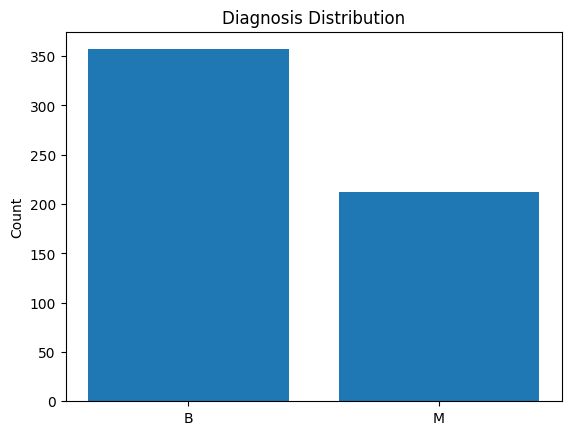

In [31]:
# diagnosis distributon

import matplotlib.pyplot as plt
counts = diagnosis_labels.value_counts()
plt.bar(counts.index, counts.values)
plt.ylabel('Count')
plt.title('Diagnosis Distribution')
plt.show()

B(benign) has 360 patients
M(malignant) has 200 patients

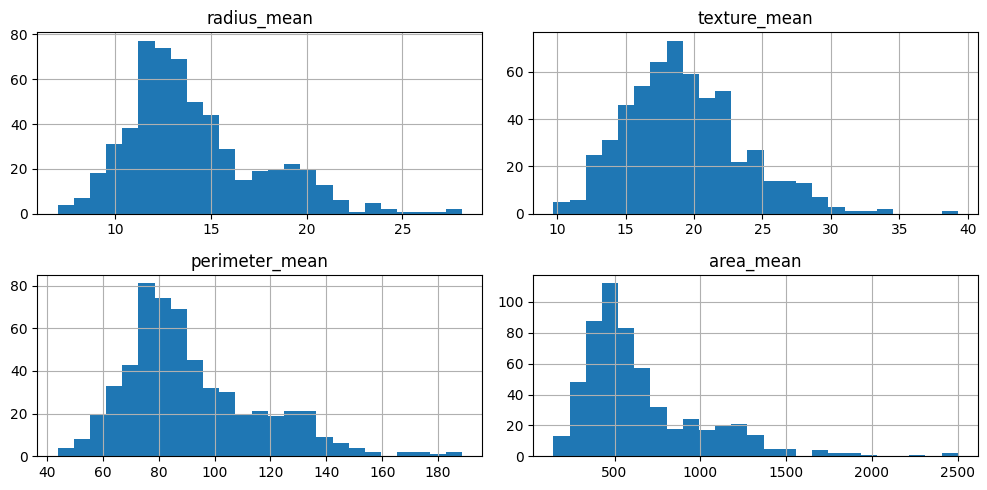

In [35]:
data[['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean']].hist(bins=25, figsize=(10,5))
plt.tight_layout()
plt.show()

all features are right skewed malignant cases create a long tail on the right
meaning the right hand side tail is longer than the left hand side

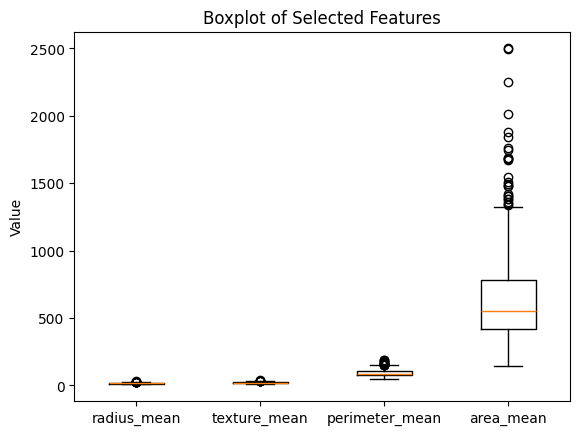

In [ ]:
plt.boxplot([data['radius_mean'], data['texture_mean'], data['perimeter_mean'], data['area_mean']])
plt.xticks([1, 2, 3, 4], ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean'])
plt.ylabel('Value') # More general label for multiple features
plt.title('Boxplot of Selected Features') # More general title
plt.show()

area mean dominates other futures
 The boxplots show that 'area_mean' and 'perimeter_mean' have higher median values and wider ranges compared to 'radius_mean' and 'texture_mean'.
right skewness, indicating the presence of larger values in malignant cases.
There are several outliers, particularly in 'area_mean' and 'perimeter_mean', which may correspond to extreme measurements in the dataset.

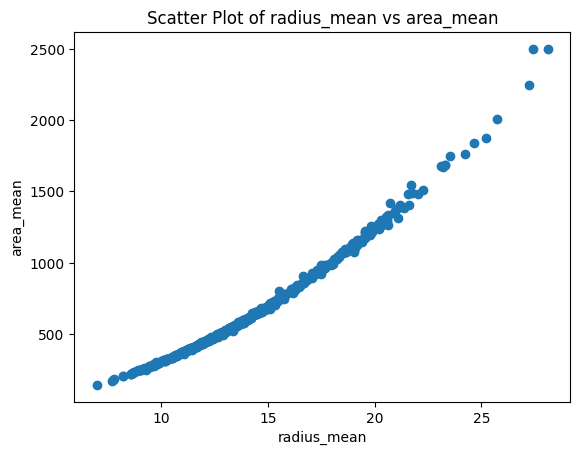

In [36]:
plt.scatter(data['radius_mean'], data['area_mean'])
plt.xlabel('radius_mean')
plt.ylabel('area_mean')
plt.title('Scatter Plot of radius_mean vs area_mean')
plt.show()

The scatter plot shows a strong positive correlation between radius_mean and area_mean, indicating that as the radius of the tumor increases, the area also increases proportionally. Most benign cases cluster at lower values, while malignant cases tend to have higher radius and area measurements, reflecting larger tumor sizes.

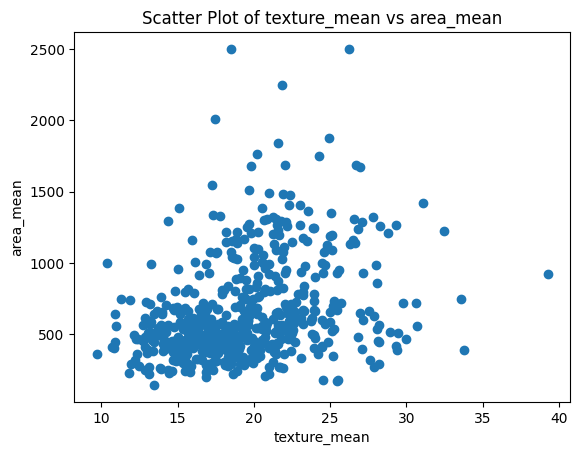

In [37]:
plt.scatter(data['texture_mean'], data['area_mean'])
plt.xlabel('texture_mean')
plt.ylabel('area_mean')
plt.title('Scatter Plot of texture_mean vs area_mean')
plt.show()

The scatter plot indicates a moderate positive correlation between texture_mean and area_mean.
 Benign cases generally cluster at lower area values with varying texture, while malignant cases tend to have both higher area and higher texture_mean values, suggesting that larger tumors often exhibit more heterogeneous textures.

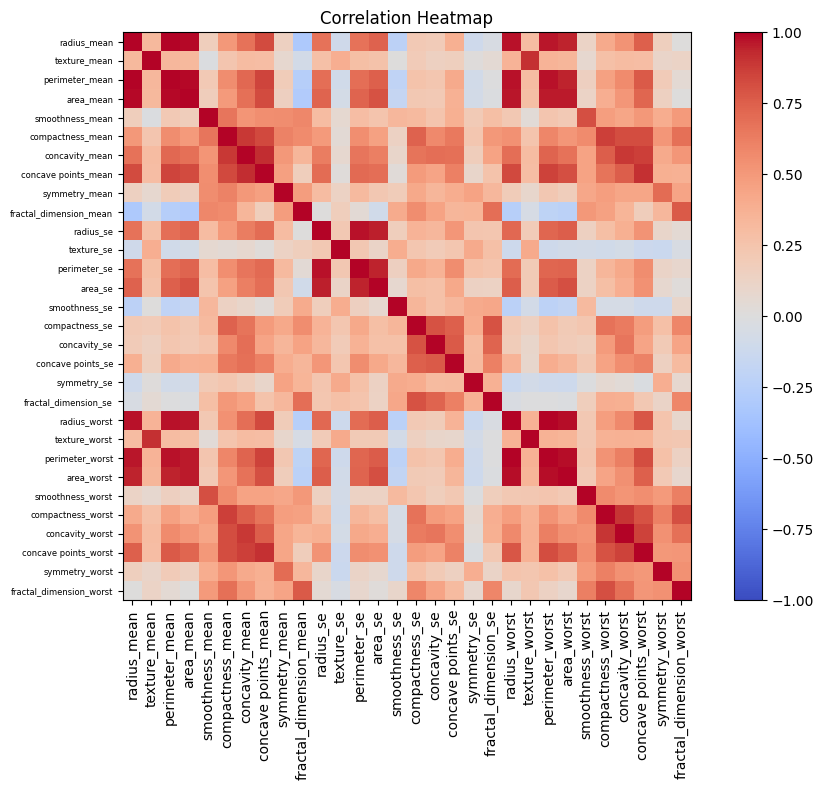

In [38]:
import matplotlib.pyplot as plt
corr = x.corr()
plt.figure(figsize=(10, 8))
plt.imshow(corr.values, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=6)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

red=+1(highly correlated)
blue=_1(negative)
white=0(no correlation)

In [39]:
corr=x.corr()
high_corr=[]
for i in range(len(corr.columns)):
  for j in range(i+1, len(corr.columns)):
    if abs(corr.iloc[i, j])>0.90:
      high_corr.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))
high_corr=sorted(high_corr, key=lambda x: abs(x[2]), reverse=True)
for f1,f2,r in high_corr:
  print(f"{f1} - {f2}: {r:.3f}")

radius_mean - perimeter_mean: 0.998
radius_worst - perimeter_worst: 0.994
radius_mean - area_mean: 0.987
perimeter_mean - area_mean: 0.987
radius_worst - area_worst: 0.984
perimeter_worst - area_worst: 0.978
radius_se - perimeter_se: 0.973
perimeter_mean - perimeter_worst: 0.970
radius_mean - radius_worst: 0.970
perimeter_mean - radius_worst: 0.969
radius_mean - perimeter_worst: 0.965
area_mean - radius_worst: 0.963
area_mean - area_worst: 0.959
area_mean - perimeter_worst: 0.959
radius_se - area_se: 0.952
perimeter_mean - area_worst: 0.942
radius_mean - area_worst: 0.941
perimeter_se - area_se: 0.938
concavity_mean - concave points_mean: 0.921
texture_mean - texture_worst: 0.912
concave points_mean - concave points_worst: 0.910


the imaging measurements show very high redundancy-radius means,perimeter mean and area-mean are almost perfecty correlated(r>0.98)because they are linked
The high correlations among features like radius_mean, perimeter_mean, and area_mean indicate that these measurements are closely linked; as the size of a tumor increases, all related dimensional features increase proportionally. Clinically, this reflects that larger tumors tend to have greater overall dimensions, so these variables provide overlapping information. Features such as concavity_mean and concave points_mean being highly correlated suggest that the irregularity or sharpness of tumor edges is consistently captured across related metrics. Understanding these redundancies helps in selecting the most informative features for modeling and reduces noise from repetitive data

In [40]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
data_scaled=scaler.fit_transform(x)
data_scaled=pd.DataFrame(data_scaled,columns=x.columns)

In [41]:
print('shape after scaling', data_scaled.shape)
print('\nMean check')
print(data_scaled.mean().head())
print('\nStandard Deviation check')
print(data_scaled.std().head())

shape after scaling (569, 30)

Mean check
radius_mean       -1.373633e-16
texture_mean       6.868164e-17
perimeter_mean    -1.248757e-16
area_mean         -2.185325e-16
smoothness_mean   -8.366672e-16
dtype: float64

Standard Deviation check
radius_mean        1.00088
texture_mean       1.00088
perimeter_mean     1.00088
area_mean          1.00088
smoothness_mean    1.00088
dtype: float64


the shape is as before no rows lost
data is now cleaned and ready for kmeans

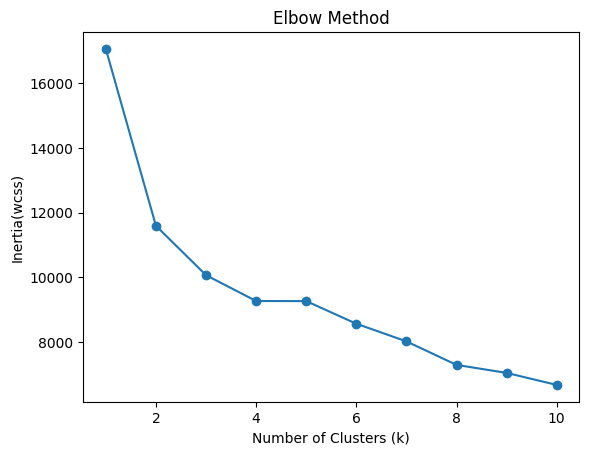

In [42]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias=[]
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    kmeans.fit(data_scaled)
    inertias.append (kmeans.inertia_) #wcss

plt.plot(range(1,11), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia(wcss)')
plt.title('Elbow Method')
plt.show()

k=2
this is the strong peek of the visible elbow in the inertia plot making it more statistically supported choice for our diagnosis

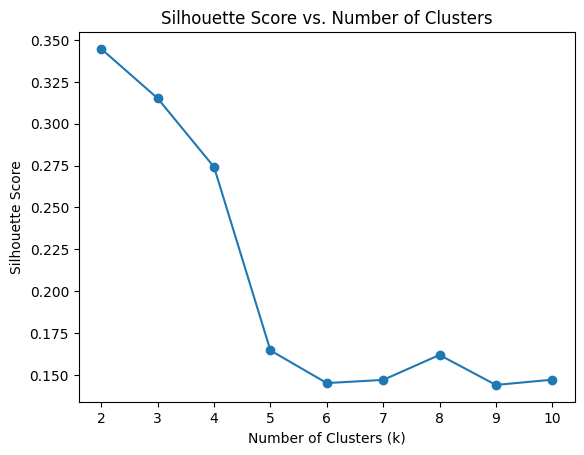

In [43]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto') # Added n_init='auto' for compatibility
    labels=kmeans.fit_predict(data_scaled)
    score=silhouette_score(data_scaled, labels)
    sil_scores.append(score)

plt.plot(range(2, 11), sil_scores, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.show()

silhouette measures how similar a point is to its own cluster vs other clusters
the highest score is at k=2 confriming that clusters gives the most coherent seperation

In [44]:
import numpy as np # Ensure numpy is imported if not already

# The following lines are redundant as data has already been cleaned and scaled.
# data_clean=data.drop(columns=['Unnamed: 32', 'id','diagnosis'])
# data_scaled=(data_clean-data_clean.mean())/data_clean.std()

# Use the pre-existing data_scaled for clustering
X=data_scaled.values
k=2
idx=np.random.choice(len(X), k, replace=False)
centroids=X[idx]

for iter in range (100):
   # Calculate Euclidean distance between each data point and each centroid
   dists=np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
   labels=np.argmin(dists, axis=1)
   new_centroids=np.array([X[labels==i].mean(axis=0) for i in range(k)])
   if np.allclose(centroids, new_centroids):
     print(f"Converged at iteration {iter}")
     break
   centroids=new_centroids

Converged at iteration 5


In [47]:
data_clean = x.copy()
model={}
model['centroids']=centroids
model['labels']=labels
model['columns']=data_clean.columns.tolist()
model['mean']=data_clean.mean().values
model['std']=data_clean.std().values

In [48]:
#assigning cluster labes to every obeservation
data['cluster']=labels # 0 or 1
data['cluster_label']=data['cluster'].map({0:'Malignant', 1:'Benign'})
data_result=data[['diagnosis', 'cluster', 'cluster_label']]
data_result.to_csv('Cancer_Data_with_cluster.csv', index=False)
print(data_result.head())
print('\ncounts')
print(data_result['cluster_label'].value_counts())

  diagnosis  cluster cluster_label
0         M        0     Malignant
1         M        0     Malignant
2         M        0     Malignant
3         M        0     Malignant
4         M        0     Malignant

counts
cluster_label
Benign       375
Malignant    194
Name: count, dtype: int64


In [49]:
#calculating the no observation in each cluster
data['cluster'].value_counts()

,count
cluster,
1,375
0,194


In [50]:
df_for_centroids = x.copy()
df_for_centroids['cluster'] = data['cluster']
centroids_original = df_for_centroids.groupby('cluster').mean()

# Redefine data_clean and data_scaled to ensure consistency with cluster labels
data_clean = x.copy() # Use 'x' as it already contains the cleaned features
data_scaled = (data_clean - data_clean.mean()) / data_clean.std()

centroids_scaled = data_scaled.groupby(data['cluster']).mean()
print(centroids_original)

         radius_mean  texture_mean  perimeter_mean   area_mean  \
cluster                                                          
0          17.414536     21.275258      115.452887  979.857216   
1          12.426691     18.262427       79.820053  486.772267   

         smoothness_mean  compactness_mean  concavity_mean  \
cluster                                                      
0               0.104808          0.157993        0.177949   
1               0.091990          0.076585        0.042679   

         concave points_mean  symmetry_mean  fractal_dimension_mean  ...  \
cluster                                                              ...   
0                   0.092921       0.197526                0.064831  ...   
1                   0.026155       0.172696                0.061746  ...   

         radius_worst  texture_worst  perimeter_worst   area_worst  \
cluster                                                              
0           21.103041      28.662320     

In [51]:
#compare the clusters(cluster 0 and cluster1)
mean_cols=[c for c in data.columns if '_mean' in c]
worst_cols=[c for c in data.columns if '_worst' in c]
cluster_means=data.groupby('cluster')[mean_cols].mean()
cluster_worst=data.groupby('cluster')[worst_cols].std()
diff = cluster_means.loc[0] - cluster_means.loc[1]
pct=(diff/cluster_means.loc[1]*100).sort_values(ascending=False)
print(pct.round(1))

concavity_mean            316.9
concave points_mean       255.3
compactness_mean          106.3
area_mean                 101.3
perimeter_mean             44.6
radius_mean                40.1
texture_mean               16.5
symmetry_mean              14.4
smoothness_mean            13.9
fractal_dimension_mean      5.0
dtype: float64


In [52]:
#cross tabulate the generated cluster
ct=pd.crosstab(data['diagnosis'], data['cluster'], rownames=['True diagnosis'], colnames=['K-Means cluster'])
ct_percent=pd.crosstab(data['diagnosis'], data['cluster'], rownames=['True diagnosis'], colnames=['K-Means cluster'], normalize='columns')
print(ct)
print(ct_percent.round(1))
print('counts:')
print('\n% within cluster:')

K-Means cluster    0    1
True diagnosis           
B                 18  339
M                176   36
K-Means cluster    0    1
True diagnosis           
B                0.1  0.9
M                0.9  0.1
counts:

% within cluster:


In [53]:
#determing the proportion of malignant and bening
# Correct 'counts' to be actual counts
counts = pd.crosstab(data['diagnosis'], data['cluster'])

# Calculate proportions normalized by column (within each cluster)
prop_by_cluster = pd.crosstab(data['diagnosis'], data['cluster'], normalize='columns')

result=pd.DataFrame({
    'n_malignant': counts.loc['M'], # Count of malignant cases in each cluster
    'n_benign': counts.loc['B'],    # Count of benign cases in each cluster
    'prop_malignant_in_cluster': prop_by_cluster.loc['M'].round(2), # Proportion of malignant cases within each cluster
    'prop_benign_in_cluster': prop_by_cluster.loc['B'].round(2),    # Proportion of benign cases within each cluster
    'total_observations_in_cluster': counts.sum(axis=0), # Total observations in each cluster
    'dominant_diagnosis_in_cluster': prop_by_cluster.idxmax(axis=0) # Dominant diagnosis label in each cluster
})
print(result)

         n_malignant  n_benign  prop_malignant_in_cluster  \
cluster                                                     
0                176        18                       0.91   
1                 36       339                       0.10   

         prop_benign_in_cluster  total_observations_in_cluster  \
cluster                                                          
0                          0.09                            194   
1                          0.90                            375   

        dominant_diagnosis_in_cluster  
cluster                                
0                                   M  
1                                   B  


In [54]:
from sklearn.metrics import silhouette_score, silhouette_samples

sil_score = silhouette_score(data_scaled, data['cluster'])
print(f"Silhouette Score(k=2): {sil_score:.4f}")

sil_samples = silhouette_samples(data_scaled, data['cluster'])
for k in [0, 1]:
    cluster_k_silhouette_scores = sil_samples[data['cluster'] == k]
    print(f"cluster{k} mean Silhouette: {cluster_k_silhouette_scores.mean():.4f}")

Silhouette Score(k=2): 0.3434
cluster0 mean Silhouette: 0.1369
cluster1 mean Silhouette: 0.4502


In [55]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2, random_state=42)
data_pca=pca.fit_transform(data_scaled)
pca_data=pd.DataFrame(data_pca, columns=['PC1', 'PC2'])
pca_data['cluster']=data['cluster'].values
pca_data['diagnosis']=data['diagnosis'].values
print(pca_data.head())
print("total 2D :{pca.explained_variance_ratio_.sum()*100:.1f%}")
print("pc1:{pca.explained_variance_ratio_[0]:.1f%}, pc2:{pca.explained_variance_ratio_[1]:.1f%}")

        PC1        PC2  cluster diagnosis
0  9.184755   1.946870        0         M
1  2.385703  -3.764859        0         M
2  5.728855  -1.074229        0         M
3  7.116691  10.266556        0         M
4  3.931842  -1.946359        0         M
total 2D :{pca.explained_variance_ratio_.sum()*100:.1f%}
pc1:{pca.explained_variance_ratio_[0]:.1f%}, pc2:{pca.explained_variance_ratio_[1]:.1f%}


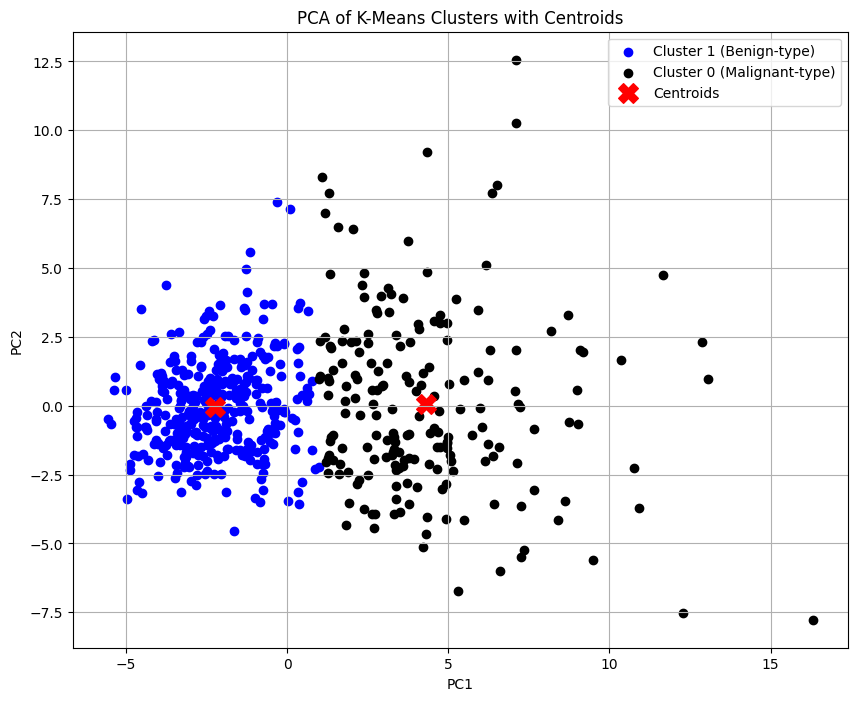

In [56]:
import matplotlib.pyplot as plt

# Transform centroids_scaled to the 2D PCA space
pca_centroids = pca.transform(centroids_scaled)

plt.figure(figsize=(10, 8))
plt.scatter(pca_data[pca_data['cluster'] == 1]['PC1'],
            pca_data[pca_data['cluster'] == 1]['PC2'],
            c='blue', label='Cluster 1 (Benign-type)')
plt.scatter(pca_data[pca_data['cluster'] == 0]['PC1'],
            pca_data[pca_data['cluster'] == 0]['PC2'],
            c='black', label='Cluster 0 (Malignant-type)')
plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1],
            marker='X', s=200, c='red', label='Centroids')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of K-Means Clusters with Centroids')
plt.legend()
plt.grid(True)
plt.show()

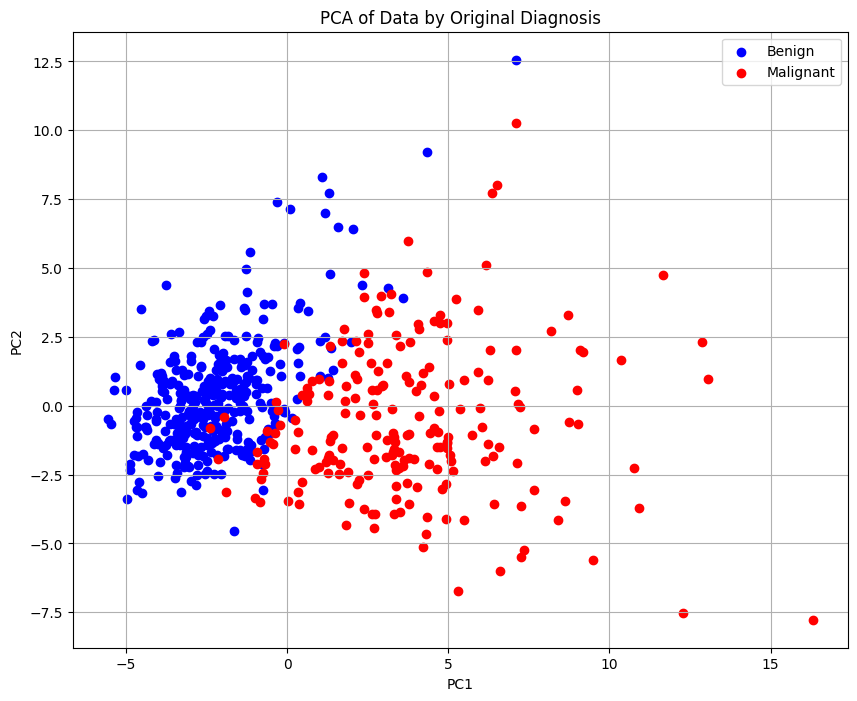

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.scatter(pca_data[pca_data['diagnosis']=='B']['PC1'],
            pca_data[pca_data['diagnosis']=='B']['PC2'],
            c='blue', label='Benign')
plt.scatter(pca_data[pca_data['diagnosis']=='M']['PC1'],
            pca_data[pca_data['diagnosis']=='M']['PC2'],
            c='red', label='Malignant')

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA of Data by Original Diagnosis')
plt.legend()
plt.grid(True)
plt.show()

In [58]:
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sil_score=silhouette_score(data_scaled, labels)
pca=PCA(n_components=2, random_state=42)
data_pca=pca.fit_transform(data_scaled)

print(f"Silhouette Score(k=2): {sil_score:.4f}")

Silhouette Score(k=2): 0.3434


In [59]:
print("x for K-Means clustering:")
print(x)
print("\ny for K-Means clustering:")
print(y)

x for K-Means clustering:
     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0          17.99         10.38          122.80     1001.0          0.11840   
1          20.57         17.77          132.90     1326.0          0.08474   
2          19.69         21.25          130.00     1203.0          0.10960   
3          11.42         20.38           77.58      386.1          0.14250   
4          20.29         14.34          135.10     1297.0          0.10030   
..           ...           ...             ...        ...              ...   
564        21.56         22.39          142.00     1479.0          0.11100   
565        20.13         28.25          131.20     1261.0          0.09780   
566        16.60         28.08          108.30      858.1          0.08455   
567        20.60         29.33          140.10     1265.0          0.11780   
568         7.76         24.54           47.92      181.0          0.05263   

     compactness_mean  concavity_mean

In [60]:
print(data.drop(columns=['diagnosis']).describe())

       radius_mean  texture_mean  perimeter_mean    area_mean  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
std           0.014064          0.052813        0.079720             0.038803   
min           0.052630          0.019380        0.000000             0.000000   
25%      

In [61]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

In [62]:
x = pd.DataFrame(x_scaled, columns=x.columns)

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
# The original line 'data=(diagnosis_encoded)=le.fit_transform(diagnosis_labels)'
# would overwrite the `data` DataFrame. The encoded labels are assigned to `diagnosis_encoded`.
diagnosis_encoded = le.fit_transform(diagnosis_labels)

# The original line 'print(diagnosis_labels, diagnosis_encoded).head()' caused an AttributeError
# because the `print()` function returns `None`, and you cannot call `.head()` on `None`.
# Additionally, `diagnosis_encoded` is a NumPy array and does not have a `.head()` method.

print("Original diagnosis labels (first 5 rows):")
print(diagnosis_labels.head())

print("\nEncoded diagnosis labels (first 5 elements):")
print(diagnosis_encoded[:5])

Original diagnosis labels (first 5 rows):
0    M
1    M
2    M
3    M
4    M
Name: diagnosis, dtype: object

Encoded diagnosis labels (first 5 elements):
[1 1 1 1 1]


The original diagnosis labels show the actual clinical classification of each tumor, with 'M' indicating malignant tumors and 'B' indicating benign tumors. The encoded diagnosis labels convert these categorical values into numerical form, which is often required for machine learning algorithms. Clinically, this encoding allows the model to process the data while preserving the distinction between benign and malignant cases, which is critical for accurate prediction and treatment planning.